# CO₂ bug in the FUT land-only spin-up + the six equilibrium variables

**What happened.** The FUT LCC land-only spin-up (`I2100ssp585Clm50BgcCropCplHist_f19_f19-20260924`, script `22b`) ran 100 years with the compset default **CO₂ = 284.32 ppm** (`CLM_CO2_TYPE = constant`). Every coupled FUT run sees **≈1140 ppm**.

**Natural control.** The PD land-only spin-up (`I2000…-20260925`, script `12b`) has the same set-up, but its CO₂ (367 ppm) matches its coupled runs. If the FUT collapse comes from CO₂, PD should show no collapse.

**How to read the figures.**
- x-axis = **land years since the shared starting state**: the coupled spin-up (1–20) is shared by both branches.
  - CTRL branch: nudged run at 21–30.
  - LCC branch: land-only 21–120 → coupled spin-up 121–140 → nudged 141–150.
- **Regions:**
  - *modified cells*: `PCT_NAT_PFT` differs, so LCC ≠ CTRL is expected (the signal).
  - *>45°N unmodified* and *tropics*: identical surfdata, so LCC − CTRL should be ≈ 0 there; any gap is spin-up history.
- Jumps at stage boundaries come from a change of forcing (land-only datm ↔ coupled, free ↔ nudged), not from drift.

**Six equilibrium variables** (`../check-spinup-equilibrium-uncomplete/clm_equilibrium_variables.txt`). Criterion: the derivative of the 20-yr rolling mean ≈ 0, with soil fields at ~1 m.
- **short-term** TWS, H2OSOI and TSOI at 1.06 m: these **must** be in equilibrium for the experiment;
- **carbon** GPP, TOTVEGC and TOTVEGN: shown for information only, equilibrium is not required.

PD also includes `PD_met` (purple): the free run that supplied the nudging winds.

Copy of `check_CO2_bug_in_land_only.ipynb` with sections 8–11 added; own cache in `check_CO2_bug_in_land_only_six_variables_outputs/cache/`.

Evidence tags: **(a)** verified · **(b)** inference · **(c)** unverified. Run on Betzy in `lcc-env`. The first run reads ~800 history files (~15 min); annual means are cached in `check_CO2_bug_in_land_only_six_variables_outputs/cache/`.

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import: HDF5 locking on /cluster/home corrupted cache files
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats, optimize
import netCDF4
import pickle
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

ARCHIVE = Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive')
CASE_ROOT = Path('~/cases/BRL_FRST_XPSN').expanduser()
MASK_FILE = Path('../lcc-modified-cells/modified_cells.nc')
OUT = Path('check_CO2_bug_in_land_only_six_variables_outputs')
CACHE = OUT / 'cache'  # regenerable annual-mean .nc
CACHE.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False

# Land-state lineage per period, oldest first. handed_on = model years completed when the restart was handed on.
STAGES = pd.DataFrame([
    ('PD',  'PD_spinup',        'shared', 'NF2000norbc_tropstratchem_spinup_f19_f19',                    'coupled',   20),
    ('PD',  'PD_met',           'MET',    'NF2000norbc_tropstratchem_met_f19_f19_20260422',              'free (met source)', np.nan),
    ('PD',  'CTRL_PD',          'CTRL',   'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925',        'nudged',    np.nan),
    ('PD',  'PD_landonly_LCC',  'LCC',    'I2000Clm50BgcCropCplHist_f19_f19-20260925',                   'land-only', 100),
    ('PD',  'PD_spinup_LCC',    'LCC',    'NF2000norbc_tropstratchem_spinup_lcc_f19_f19-20260928',       'coupled',   20),
    ('PD',  'LCC_PD',           'LCC',    'NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261005',         'nudged',    np.nan),
    ('FUT', 'FUT_spinup',       'shared', 'NF2100ssp585norbc_tropstratchem_spinup_f19_f19-3',            'coupled',   20),
    ('FUT', 'CTRL_FUT',         'CTRL',   'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20260925',  'nudged',    np.nan),
    ('FUT', 'FUT_landonly_LCC', 'LCC',    'I2100ssp585Clm50BgcCropCplHist_f19_f19-20260924',             'land-only', 100),
    ('FUT', 'FUT_spinup_LCC',   'LCC',    'NF2100ssp585norbc_tropstratchem_spinup_lcc_f19_f19-20260928', 'coupled',   20),
    ('FUT', 'LCC_FUT',          'LCC',    'NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261005',   'nudged',    np.nan),
], columns=['period', 'stage', 'branch', 'case', 'kind', 'handed_on']).set_index('stage')

VARS = ['TLAI', 'TSAI', 'HTOP', 'TOTVEGC', 'GPP', 'TOTVEGN', 'TWS', 'H2OSOI_1m', 'TSOI_1m']  # missing ones skipped per stage
SOIL = {'H2OSOI_1m': 'H2OSOI', 'TSOI_1m': 'TSOI'}
SOIL_INDEX = 8  # levgrnd[8] = 1.06 m; levsoi = first 20 levgrnd levels (asserted below)
ENDSTATE_VARS = ['TLAI', 'TSAI', 'HTOP', 'TOTVEGC', 'GPP']
SHORT_TERM = ['TWS', 'H2OSOI_1m', 'TSOI_1m']
CARBON = ['GPP', 'TOTVEGC', 'TOTVEGN']
ROLL = 20
LINEAGE_VARS = ['TLAI', 'TOTVEGC']
NUDGED_YEARS = (2001, 2009)
COLOR = {'shared': '0.35', 'CTRL': '#1f77b4', 'LCC': '#d95f02', 'MET': '#7b3294'}  # MET = free PD run that supplied the nudging winds

## 1. CO₂ per stage

`CLM_CO2_TYPE` and `CCSM_CO2_PPMV` are read from each case's `env_run.xml`. With `constant`, CLM uses `CCSM_CO2_PPMV`; with `diagnostic`, it uses the atmosphere's CO₂.
"CO₂ seen" = median of `PCO2 / PBOT` in the last h0 file, where the field exists. It is not in the land-only output or the LCC coupled spin-ups.

In [2]:
def hist_files(case):
    files = sorted((ARCHIVE / case / 'lnd/hist').glob('*.clm2.h0.*.nc'))
    if not files:
        raise FileNotFoundError(f'No clm2.h0 files for {case}')
    return files

def xml_value(case, key):
    for root in (CASE_ROOT, CASE_ROOT / 'BRL_FRST_XPSN_archive'):
        for xml in sorted((root / case).glob('env_*.xml')):
            match = re.search(rf'<entry id="{key}" value="([^"]*)"', xml.read_text())
            if match:
                return match.group(1)
    return 'n/a'

rows = []
for stage, s in STAGES.iterrows():
    with netCDF4.Dataset(hist_files(s.case)[-1]) as d:
        seen = float(np.ma.median(d['PCO2'][:] / d['PBOT'][:]) * 1e6) if {'PCO2', 'PBOT'} <= set(d.variables) else np.nan
    rows.append(dict(stage=stage, period=s.period, branch=s.branch, kind=s.kind,
                     CLM_CO2_TYPE=xml_value(s.case, 'CLM_CO2_TYPE'), CCSM_CO2_PPMV=xml_value(s.case, 'CCSM_CO2_PPMV'),
                     co2_seen_ppm=round(seen, 1)))
co2 = pd.DataFrame(rows).set_index('stage')
co2.to_csv(OUT / 'co2_per_stage.csv')
display(co2)

,period,branch,kind,CLM_CO2_TYPE,CCSM_CO2_PPMV,co2_seen_ppm
stage,,,,,,
PD_spinup,PD,shared,coupled,diagnostic,367.0,370.3
PD_met,PD,MET,free (met source),diagnostic,367.0,370.3
CTRL_PD,PD,CTRL,nudged,diagnostic,367.0,370.3
PD_landonly_LCC,PD,LCC,land-only,constant,367.0,NaN
PD_spinup_LCC,PD,LCC,coupled,diagnostic,367.0,NaN
LCC_PD,PD,LCC,nudged,diagnostic,367.0,370.3
FUT_spinup,FUT,shared,coupled,diagnostic,284.32,1134.0
CTRL_FUT,FUT,CTRL,nudged,diagnostic,284.32,1142.0
FUT_landonly_LCC,FUT,LCC,land-only,constant,284.32,NaN


## 2. Annual means

Annual means are weighted by the `time_bounds` length; each interval goes to its midpoint year, and years with less than 365 days are dropped. Spatial weights are `area × landfrac`.

In [3]:
N_WORKERS = 8  # parallel file readers

def read_file(path):
    # Plain netCDF4: ~0.3 s per file on NIRD vs ~5 s with xarray.open_dataset (decoding all 52 variables).
    with netCDF4.Dataset(path) as d:
        t = d['time']
        assert t.calendar == 'noleap' and re.fullmatch(r'days since \d{4}-01-01( 00:00:00)?', t.units), (path, t.units)
        bounds = d['time_bounds'][:].astype(float)
        mid = bounds.mean(1)  # each interval goes to its midpoint year (bounds start 30 min early)
        out = dict(mid=mid, year=int(t.units.split()[2][:4]) + np.floor(mid / 365).astype(int),
                   days=bounds[:, 1] - bounds[:, 0])
        for v in VARS:
            if v in d.variables:
                out[v] = np.ma.filled(d[v][:].astype(float), np.nan)
        for new, old in SOIL.items():
            if old in d.variables:
                assert abs(float(d['levgrnd'][SOIL_INDEX]) - 1.06) < 0.01, f'{path}: soil levels changed'
                assert len(d.dimensions['levsoi']) <= len(d.dimensions['levgrnd'])
                out[new] = np.ma.filled(d[old][:, SOIL_INDEX].astype(float), np.nan)
    return out

def annual_means(case):
    files = hist_files(case)
    try:
        with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:
            parts = list(pool.map(read_file, files))
    except pickle.PicklingError:  # cells exec'd outside a kernel (read_file not in __main__): read serially
        parts = [read_file(f) for f in files]
    mid = np.concatenate([p['mid'] for p in parts])
    if len(np.unique(mid)) != len(mid):
        raise ValueError(f'{case}: duplicated time steps')
    year = np.concatenate([p['year'] for p in parts])
    days = np.concatenate([p['days'] for p in parts])
    keep = [y for y in np.unique(year) if abs(days[year == y].sum() - 365) < 0.5]  # complete years only
    with netCDF4.Dataset(files[0]) as d:
        coords = dict(lat=d['lat'][:].data, lon=d['lon'][:].data)
        grid = {v: (('lat', 'lon'), np.ma.filled(d[v][:].astype(float), np.nan)) for v in ('area', 'landfrac')}
        source = lambda v: d[SOIL.get(v, v)]
        attrs = {v: {a: source(v).getncattr(a) for a in ('units', 'long_name') if a in source(v).ncattrs()}
                 for v in VARS if SOIL.get(v, v) in d.variables}
    data = {}
    for v in [v for v in VARS if all(v in p for p in parts)]:
        x = np.concatenate([p[v] for p in parts])
        rows = []
        for y in keep:
            sel = year == y
            total = np.nansum(x[sel] * days[sel][:, None, None], 0)
            total[np.isnan(x[sel]).all(0)] = np.nan
            rows.append(total / days[sel].sum())
        data[v] = (('year', 'lat', 'lon'), np.stack(rows), {**attrs.get(v, {}), **({'depth_m': 1.06} if v in SOIL else {})})
    return xr.Dataset({**data, **grid}, coords=dict(year=keep, **coords))

def load_stage(stage):
    path = CACHE / f'annual_{stage}.nc'
    if path.is_file() and not REBUILD_CACHE:
        try:
            with xr.open_dataset(path) as ds:
                return ds.load()
        except OSError:
            print(f'{path.name}: unreadable cache, rebuilding')
    ann = annual_means(STAGES.loc[stage, 'case'])
    tmp = path.with_name(path.stem + '.tmp.nc')
    ann.to_netcdf(tmp)
    os.replace(tmp, path)  # never leave a half-written cache behind
    return ann

ANN = {stage: load_stage(stage) for stage in STAGES.index}
ref = ANN['CTRL_FUT']
for stage, a in ANN.items():
    assert np.array_equal(a.lat, ref.lat) and np.array_equal(a.lon, ref.lon), stage
    assert np.allclose(a.landfrac, ref.landfrac, equal_nan=True), stage
print(pd.Series({s: f"{int(a.year[0])}–{int(a.year[-1])} ({a.sizes['year']} yr): {', '.join(v for v in VARS if v in a)}"
                 for s, a in ANN.items()}).to_string())

PD_spinup           1–20 (20 yr): TLAI, TSAI, HTOP, TOTVEGC, GPP, ...
PD_met              2000–2014 (15 yr): TLAI, TSAI, HTOP, TOTVEGC, ...
CTRL_PD             2000–2009 (10 yr): TLAI, TSAI, HTOP, TOTVEGC, ...
PD_landonly_LCC     1–100 (100 yr): TLAI, TOTVEGC, GPP, H2OSOI_1m,...
PD_spinup_LCC       1–20 (20 yr): TLAI, TOTVEGC, GPP, H2OSOI_1m, T...
LCC_PD              2000–2009 (10 yr): TLAI, TSAI, HTOP, TOTVEGC, ...
FUT_spinup          1–20 (20 yr): TLAI, TSAI, HTOP, TOTVEGC, GPP, ...
CTRL_FUT            2000–2009 (10 yr): TLAI, TSAI, HTOP, TOTVEGC, ...
FUT_landonly_LCC    1–100 (100 yr): TLAI, TOTVEGC, GPP, H2OSOI_1m,...
FUT_spinup_LCC      1–20 (20 yr): TLAI, TOTVEGC, GPP, H2OSOI_1m, T...
LCC_FUT             2000–2009 (10 yr): TLAI, TSAI, HTOP, TOTVEGC, ...


In [4]:
mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, ref.lat) and np.allclose(mask.lon, ref.lon)
mask = mask.assign_coords(lat=ref.lat, lon=ref.lon)
LAND = ref.landfrac > 0
LAT = ref.lat.broadcast_like(LAND)
REGIONS = {
    'modified cells': LAND & mask,
    '>45N unmodified': LAND & (LAT > 45) & ~mask,
    'tropics 30S-30N': LAND & (abs(LAT) <= 30),
}
W = ref.area * ref.landfrac

def regional_mean(field, region):
    w = W.where(REGIONS[region] & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

def per_year(v, field):
    return field * 86400 * 365 if v == 'GPP' else field

# x-axis: land years since the shared starting state, per period.
AXIS = {}
for period, group in STAGES.groupby('period', sort=False):
    end_of = {'shared': 0}
    for stage, s in group.iterrows():
        ann = ANN[stage]
        start = 0 if s.branch == 'shared' else end_of.get(s.branch, end_of['shared'])
        n = ann.year - int(ann.year[0]) + 1
        if pd.notna(s.handed_on):
            assert int(n.max()) >= s.handed_on, stage
            ANN[stage] = ann = ann.sel(year=ann.year[n <= s.handed_on])
            n = n[n <= s.handed_on]
            end_of[s.branch] = start + int(s.handed_on)
        AXIS[stage] = start + n.values
print({k: (int(v[0]), int(v[-1])) for k, v in AXIS.items()})

SERIES = {(stage, r, v): regional_mean(per_year(v, ANN[stage][v]), r)
          for stage in STAGES.index for r in REGIONS for v in VARS if v in ANN[stage]}

{'PD_spinup': (1, 20), 'PD_met': (21, 35), 'CTRL_PD': (21, 30), 'PD_landonly_LCC': (21, 120), 'PD_spinup_LCC': (121, 140), 'LCC_PD': (141, 150), 'FUT_spinup': (1, 20), 'CTRL_FUT': (21, 30), 'FUT_landonly_LCC': (21, 120), 'FUT_spinup_LCC': (121, 140), 'LCC_FUT': (141, 150)}


## 3. The bug in one picture

Top row: **PD** (land-only at 367 ppm). Bottom row: **FUT** (land-only at 284 ppm). Dashed line = land-only stage; the CO₂ used by CLM is written above each stage.

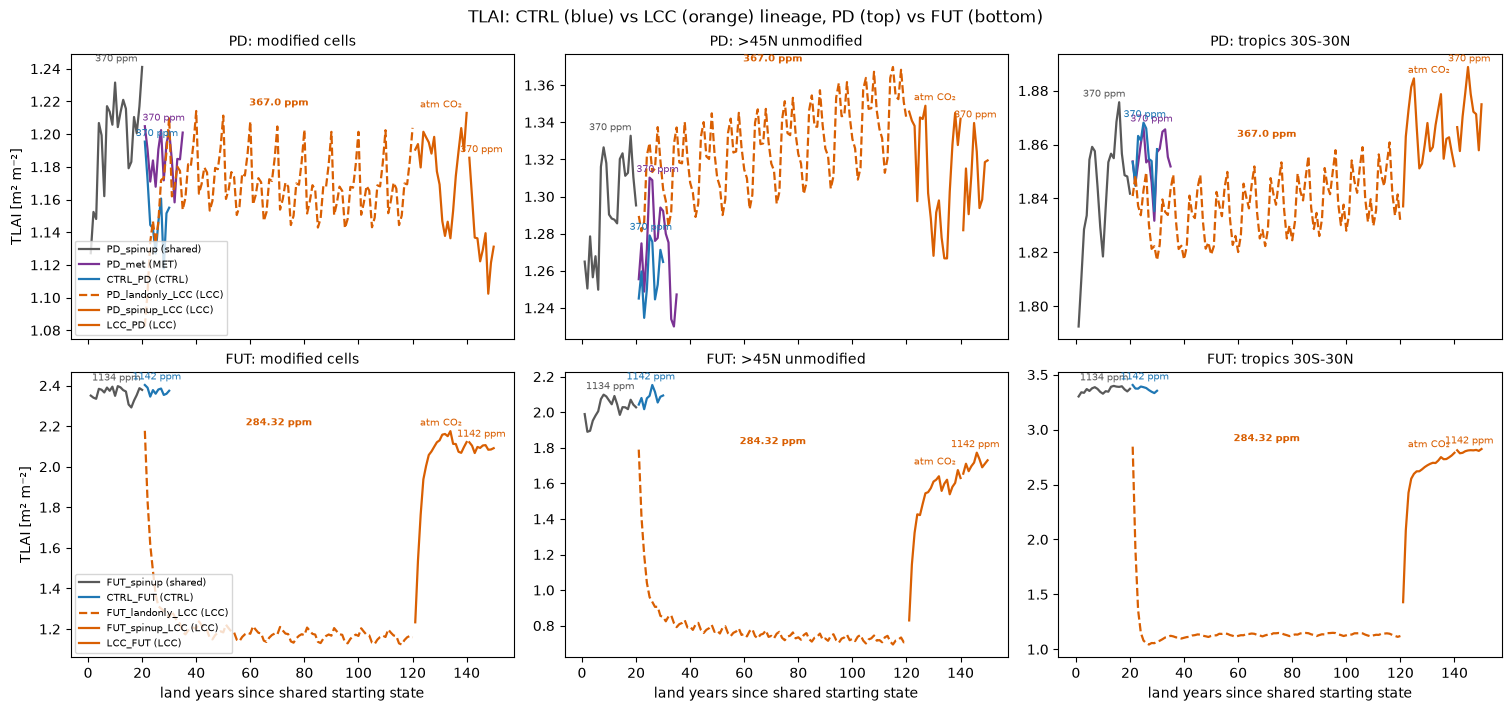

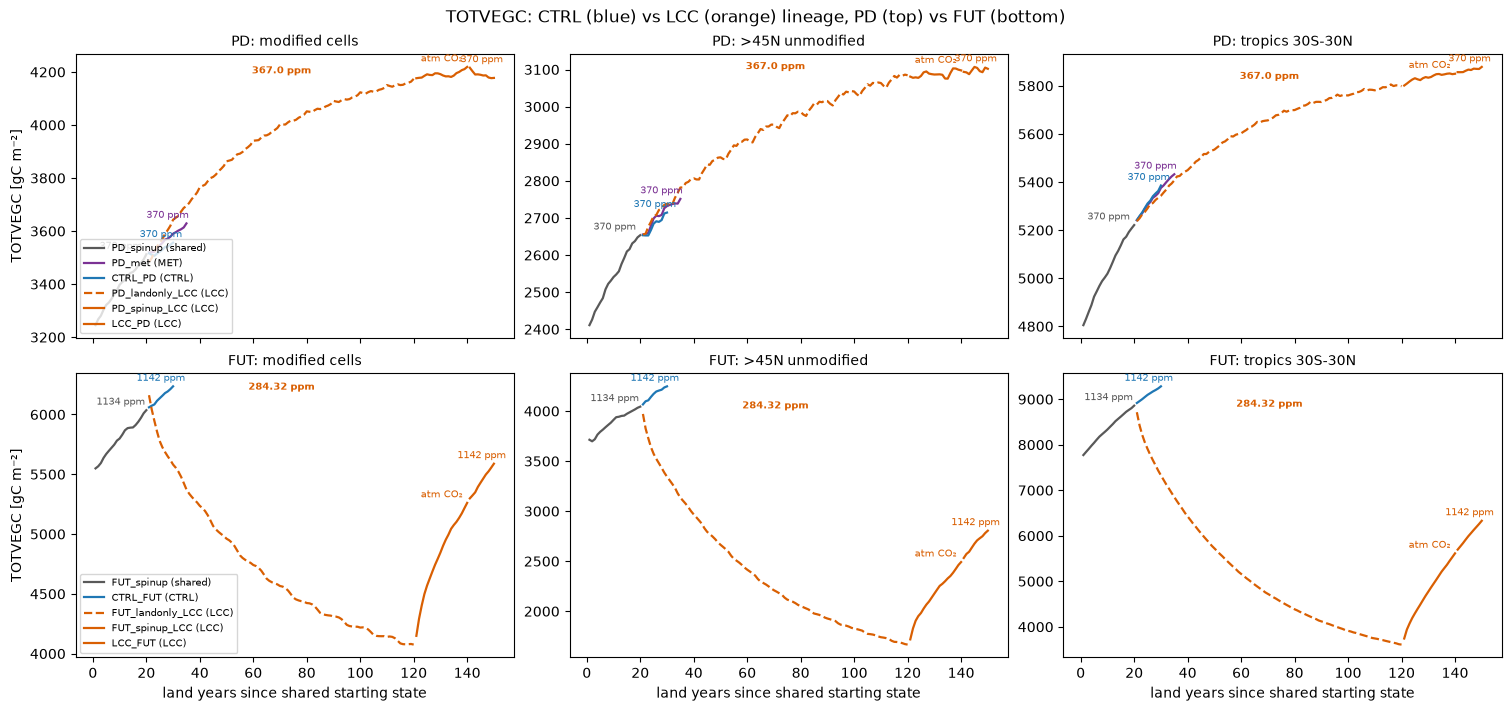

In [5]:
def lineage_figure(v, units):
    fig, axes = plt.subplots(2, len(REGIONS), figsize=(5 * len(REGIONS), 7), sharex=True, layout='constrained')
    for i, period in enumerate(['PD', 'FUT']):
        for j, region in enumerate(REGIONS):
            ax = axes[i, j]
            for stage, s in STAGES[STAGES.period == period].iterrows():
                y = SERIES[stage, region, v]
                ax.plot(AXIS[stage], y, color=COLOR[s.branch], lw=1.6, ls='--' if s.kind == 'land-only' else '-',
                        label=f'{stage} ({s.branch})')
                ppm = co2.loc[stage, 'co2_seen_ppm']
                if not np.isnan(ppm):
                    label = f'{ppm:.0f} ppm'
                elif co2.loc[stage, 'CLM_CO2_TYPE'] == 'constant':
                    label = f"{co2.loc[stage, 'CCSM_CO2_PPMV']} ppm"
                else:
                    label = 'atm CO₂'
                ax.annotate(label, (AXIS[stage].mean(), float(y.max())), textcoords='offset points',
                            xytext=(0, 4), ha='center', fontsize=7, color=COLOR[s.branch],
                            weight='bold' if s.kind == 'land-only' else 'normal')
            ax.set_title(f'{period}: {region}', fontsize=10)
            if j == 0:
                ax.set_ylabel(f'{v} [{units}]')
            if i == 1:
                ax.set_xlabel('land years since shared starting state')
        axes[i, 0].legend(fontsize=7, loc='lower left')
    fig.suptitle(f'{v}: CTRL (blue) vs LCC (orange) lineage, PD (top) vs FUT (bottom)')
    fig.savefig(OUT / f'fig1_lineage_{v}.png', dpi=150)
    plt.show()

lineage_figure('TLAI', 'm² m⁻²')
lineage_figure('TOTVEGC', 'gC m⁻²')

## 4. Why the per-run equilibrium checks did not catch it

Left: what a drift check of a single run sees. The FUT land-only TLAI in the modified cells is flat after a few years, so it "passes".
Right: what a cross-member check sees. In the nudged years, the unmodified >45°N cells (identical surfdata) differ between LCC and CTRL in FUT but hardly in PD.

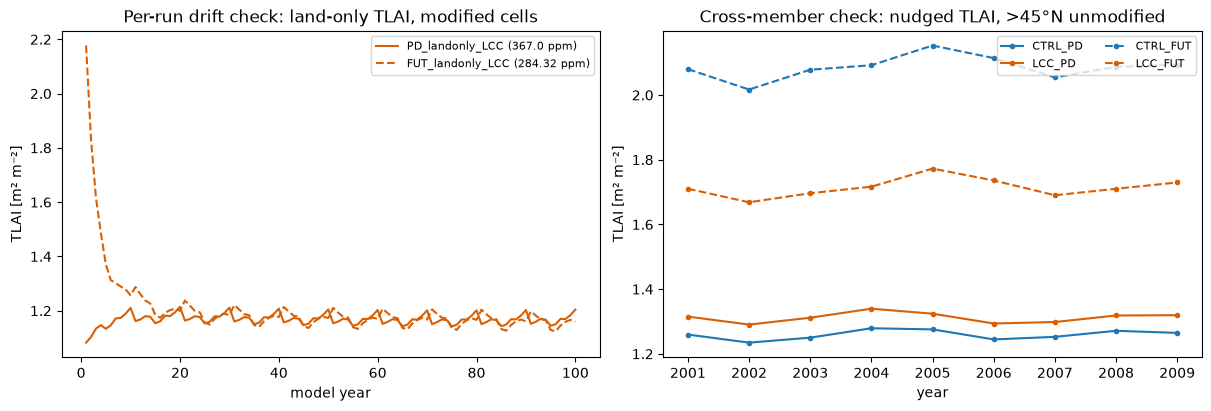

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for period, ls in [('PD', '-'), ('FUT', '--')]:
    stage = f'{period}_landonly_LCC'
    y = SERIES[stage, 'modified cells', 'TLAI']
    axes[0].plot(y.year, y, ls=ls, color=COLOR['LCC'], label=f'{stage} ({co2.loc[stage, "CCSM_CO2_PPMV"]} ppm)')
axes[0].set(title='Per-run drift check: land-only TLAI, modified cells', xlabel='model year', ylabel='TLAI [m² m⁻²]')
axes[0].legend(fontsize=8)
for period, ls in [('PD', '-'), ('FUT', '--')]:
    for branch in ('CTRL', 'LCC'):
        y = SERIES[f'{branch}_{period}', '>45N unmodified', 'TLAI'].sel(year=slice(*NUDGED_YEARS))
        axes[1].plot(y.year, y, ls=ls, marker='o', ms=3, color=COLOR[branch], label=f'{branch}_{period}')
axes[1].set(title='Cross-member check: nudged TLAI, >45°N unmodified', xlabel='year', ylabel='TLAI [m² m⁻²]')
axes[1].legend(fontsize=8, ncol=2)
fig.savefig(OUT / 'fig2_drift_vs_cross_member.png', dpi=150)
plt.show()

## 5. Consequences for the analysis: LCC − CTRL, 2001–2009

Difference of the 9-year regional means, in % of CTRL, for PD (correct CO₂) and FUT (CO₂ bug). HTOP = canopy top height and TSAI = stem area index; together with TLAI they set the snow masking (albedo). TLAI also drives MEGAN.

period                      PD   FUT
region          variable            
>45N unmodified GPP        2.6  -9.6
                HTOP       5.4 -20.2
                TLAI       4.2 -17.8
                TOTVEGC   15.4 -35.5
                TSAI       2.3  -9.1
modified cells  GPP       -1.5  -7.3
                HTOP      12.7  -0.9
                TLAI      -1.3 -11.7
                TOTVEGC   18.6 -11.3
                TSAI       0.9  -7.1
tropics 30S-30N GPP       -0.4 -11.0
                HTOP       3.9 -18.3
                TLAI       0.9 -16.6
                TOTVEGC   10.2 -33.7
                TSAI       2.2  -4.1

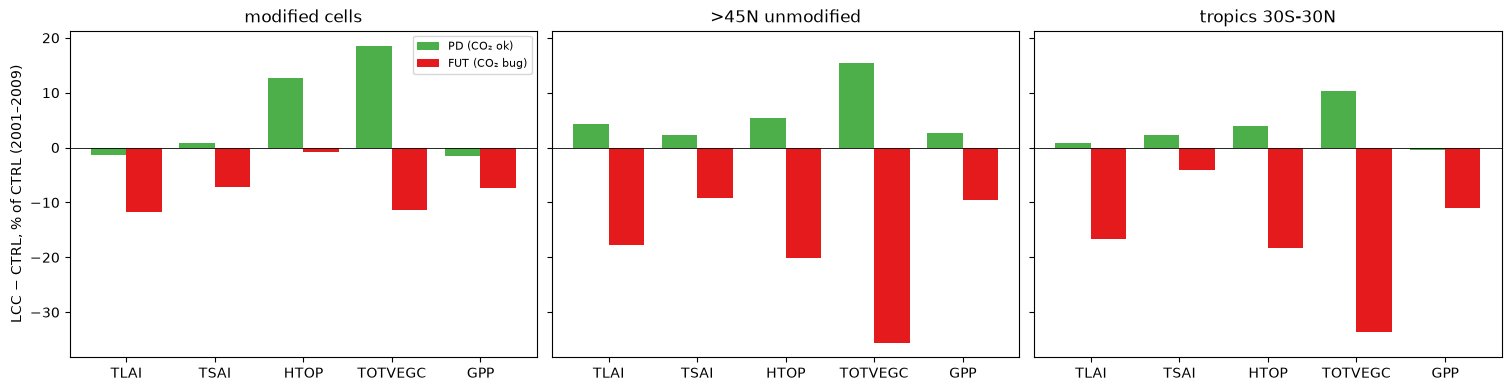

In [7]:
rows = []
for period in ('PD', 'FUT'):
    for region in REGIONS:
        for v in ENDSTATE_VARS:
            c = SERIES[f'CTRL_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            l = SERIES[f'LCC_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            rows.append(dict(period=period, region=region, variable=v, CTRL=float(c.mean()), LCC=float(l.mean()),
                             delta_pct=float(100 * (l.mean() - c.mean()) / c.mean()),
                             p_welch=stats.ttest_ind(l.values, c.values, equal_var=False).pvalue))
endstate = pd.DataFrame(rows)
endstate.to_csv(OUT / 'endstate_LCC_minus_CTRL.csv', index=False)
display(endstate.pivot_table(index=['region', 'variable'], columns='period', values='delta_pct')[['PD', 'FUT']].round(1))

fig, axes = plt.subplots(1, len(REGIONS), figsize=(5 * len(REGIONS), 3.8), sharey=True, layout='constrained')
x = np.arange(len(ENDSTATE_VARS))
for ax, region in zip(axes, REGIONS):
    sub = endstate[endstate.region == region].set_index(['period', 'variable']).delta_pct
    ax.bar(x - 0.2, [sub['PD', v] for v in ENDSTATE_VARS], 0.4, color='#4daf4a', label='PD (CO₂ ok)')
    ax.bar(x + 0.2, [sub['FUT', v] for v in ENDSTATE_VARS], 0.4, color='#e41a1c', label='FUT (CO₂ bug)')
    ax.axhline(0, color='k', lw=0.6)
    ax.set(xticks=x, xticklabels=ENDSTATE_VARS, title=region)
axes[0].set_ylabel('LCC − CTRL, % of CTRL (2001–2009)')
axes[0].legend(fontsize=8)
fig.savefig(OUT / 'fig3_endstate_PD_vs_FUT.png', dpi=150)
plt.show()

## 6. Trends: is anything still drifting?

OLS trend over the last 10 years of each stage, in % per decade of that stage's mean, with the interannual SD (in % of the mean) for scale.

In [8]:
rows = []
for (stage, region, v), y in SERIES.items():
    if v not in LINEAGE_VARS + ['GPP']:
        continue
    last = y.isel(year=slice(-10, None))
    slope = 10 * np.polyfit(last.year.values.astype(float), last.values, 1)[0]
    rows.append(dict(stage=stage, region=region, variable=v,
                     trend_pct_per_decade=100 * slope / float(last.mean()),
                     iav_sd_pct=100 * float(last.std(ddof=1) / last.mean())))
trends = pd.DataFrame(rows)
trends.to_csv(OUT / 'trends_last10yr.csv', index=False)
display(trends.pivot_table(index=['variable', 'region'], columns='stage',
                           values='trend_pct_per_decade')[list(STAGES.index)].round(1))

stage                     PD_spinup  PD_met  CTRL_PD  PD_landonly_LCC  \
variable region                                                         
GPP      >45N unmodified       -0.0    -4.4      0.2              1.1   
         modified cells         4.5    -1.6      1.0              5.3   
         tropics 30S-30N       -1.6     0.5      0.3             -1.8   
TLAI     >45N unmodified        2.0    -5.5      1.6              2.5   
         modified cells         1.2    -0.5     -3.0              3.4   
         tropics 30S-30N       -0.1     0.6     -0.3             -0.7   
TOTVEGC  >45N unmodified        4.7     1.9      2.8              1.2   
         modified cells         3.2     2.1      1.5              0.6   
         tropics 30S-30N        3.9     2.4      2.9              0.3   

stage                     PD_spinup_LCC  LCC_PD  FUT_spinup  CTRL_FUT  \
variable region                                                         
GPP      >45N unmodified            5.1    -0.3         0.4      -0.3   
         modified cells            10.3    -1.7        -0.4       1.1   
         tropics 30S-30N           -0.9     0.8        -0.3      -0.9   
TLAI     >45N unmodified            5.7     1.5        -0.8       2.5   
         modified cells             7.4    -4.9        -1.2      -1.0   
         tropics 30S-30N           -0.5     0.2         0.1      -1.8   
TOTVEGC  >45N unmodified            0.7     0.4         3.1       4.9   
         modified cells             1.0    -0.9         3.5       3.3   
         tropics 30S-30N            0.2     0.4         5.9       4.4   

stage                     FUT_landonly_LCC  FUT_spinup_LCC  LCC_FUT  
variable region                                                      
GPP      >45N unmodified               0.3             1.3     -0.9  
         modified cells               -1.8            -3.9      0.7  
         tropics 30S-30N              -1.2             0.0     -0.3  
TLAI     >45N unmodified              -0.9             1.6      3.4  
         modified cells               -3.0            -4.3     -0.8  
         tropics 30S-30N              -2.0             3.7      0.9  
TOTVEGC  >45N unmodified              -4.7            12.8     11.3  
         modified cells               -2.0             7.5      6.1  
         tropics 30S-30N              -3.8            15.9     11.7

## 7. Recovery after CO₂ is restored (FUT LCC branch)

Fit X(t) = A − B·exp(−t/τ) to the LCC series from the start of the coupled spin-up (land year 121) to the end of LCC_FUT (150). Then estimate when it would reach the CTRL_FUT 2001–2009 level. This is descriptive: it extrapolates a 30-year record (b).

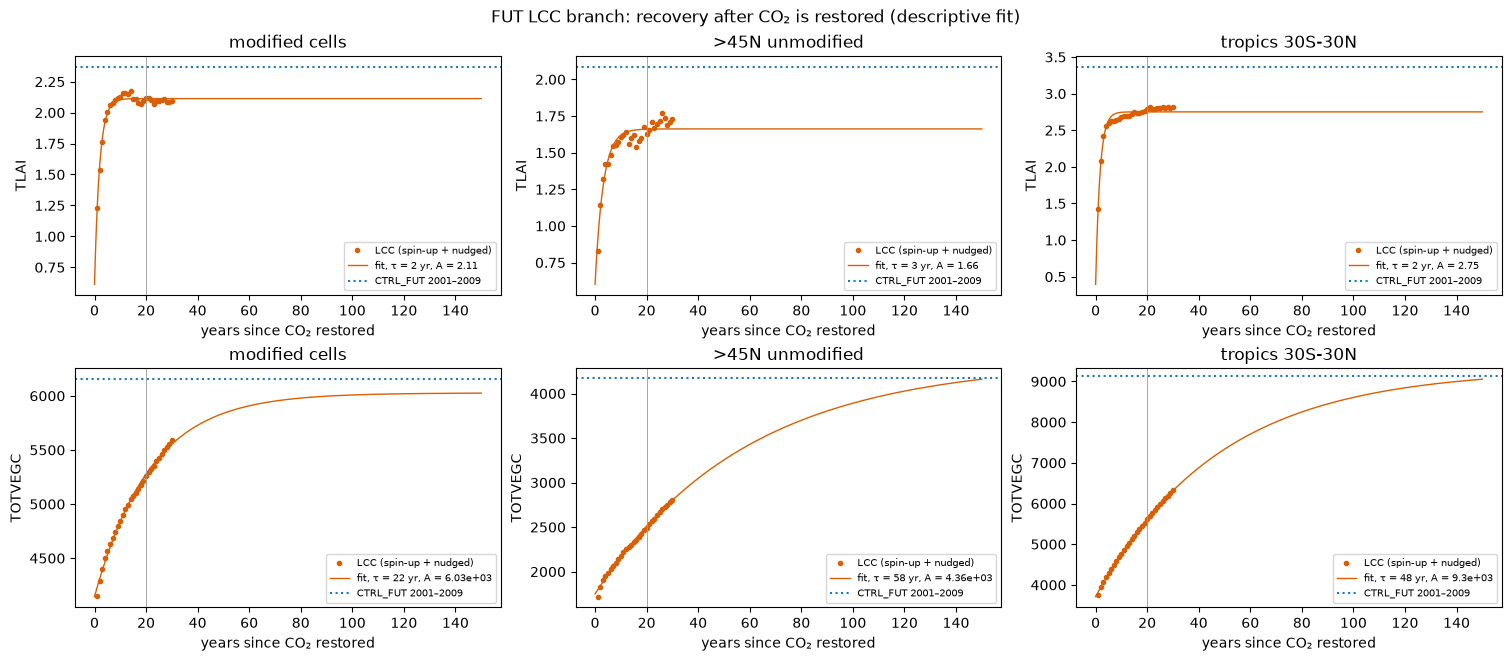

,region,variable,tau_yr,asymptote,ctrl_level,now,years_to_reach_ctrl,gap_now_pct
0,modified cells,TLAI,1.96,2.11,2.37,2.09,inf,-11.74
1,>45N unmodified,TLAI,3.13,1.66,2.09,1.73,inf,-17.06
2,tropics 30S-30N,TLAI,1.66,2.75,3.37,2.82,inf,-16.12
3,modified cells,TOTVEGC,21.73,6026.84,6153.63,5588.40,inf,-9.19
4,>45N unmodified,TOTVEGC,58.17,4359.09,4179.55,2805.25,155.66,-32.88
5,tropics 30S-30N,TOTVEGC,47.79,9297.29,9124.91,6329.32,166.22,-30.64


In [9]:
def recovery(region, v):
    t = np.r_[AXIS['FUT_spinup_LCC'], AXIS['LCC_FUT']] - 120.0
    y = np.r_[SERIES['FUT_spinup_LCC', region, v].values, SERIES['LCC_FUT', region, v].values]
    target = float(SERIES['CTRL_FUT', region, v].sel(year=slice(*NUDGED_YEARS)).mean())
    f = lambda t, A, B, tau: A - B * np.exp(-t / tau)
    p, _ = optimize.curve_fit(f, t, y, p0=(y[-1] * 1.2, y[-1] - y[0], 30), maxfev=20000)
    A, B, tau = p
    reach = tau * np.log(B / (A - target)) if A > target else np.inf
    return t, y, f, p, target, reach

rows = []
fig, axes = plt.subplots(len(LINEAGE_VARS), len(REGIONS), figsize=(5 * len(REGIONS), 6.5), layout='constrained')
for i, v in enumerate(LINEAGE_VARS):
    for j, region in enumerate(REGIONS):
        ax = axes[i, j]
        t, y, f, p, target, reach = recovery(region, v)
        tt = np.linspace(0, 150, 300)
        ax.plot(t, y, 'o', ms=3, color=COLOR['LCC'], label='LCC (spin-up + nudged)')
        ax.plot(tt, f(tt, *p), color=COLOR['LCC'], lw=1, label=f'fit, τ = {p[2]:.0f} yr, A = {p[0]:.3g}')
        ax.axhline(target, color=COLOR['CTRL'], ls=':', label='CTRL_FUT 2001–2009')
        ax.axvline(20, color='0.6', lw=0.6)
        ax.set(title=f'{region}', xlabel='years since CO₂ restored', ylabel=v)
        ax.legend(fontsize=7)
        rows.append(dict(region=region, variable=v, tau_yr=p[2], asymptote=p[0], ctrl_level=target,
                         now=float(y[-1]), years_to_reach_ctrl=reach,
                         gap_now_pct=100 * (y[-1] - target) / target))
fig.suptitle('FUT LCC branch: recovery after CO₂ is restored (descriptive fit)')
fig.savefig(OUT / 'fig4_recovery_fit.png', dpi=150)
plt.show()
recov = pd.DataFrame(rows)
recov.to_csv(OUT / 'recovery_fit.csv', index=False)
display(recov.round(2))

## 8. The six equilibrium variables along the spin-up lineage

Purple (PD only) = `PD_met`, the free continuation of the PD spin-up (2000–2014, same forcing) that supplied the nudging winds. Compare it with the nudged CTRL_PD over the same years to see the effect of nudging (details in `../impact-of-nudging-on-land/`).

One figure per variable: short-term first (TWS, H2OSOI and TSOI at 1.06 m), then carbon (GPP, TOTVEGC, TOTVEGN). Thin lines show annual means, thick lines the **20-yr trailing rolling mean**, drawn only for stages of at least 20 years.
TWS and TOTVEGN were not saved in the land-only runs or the LCC coupled spin-ups; each panel lists the stages that are missing.

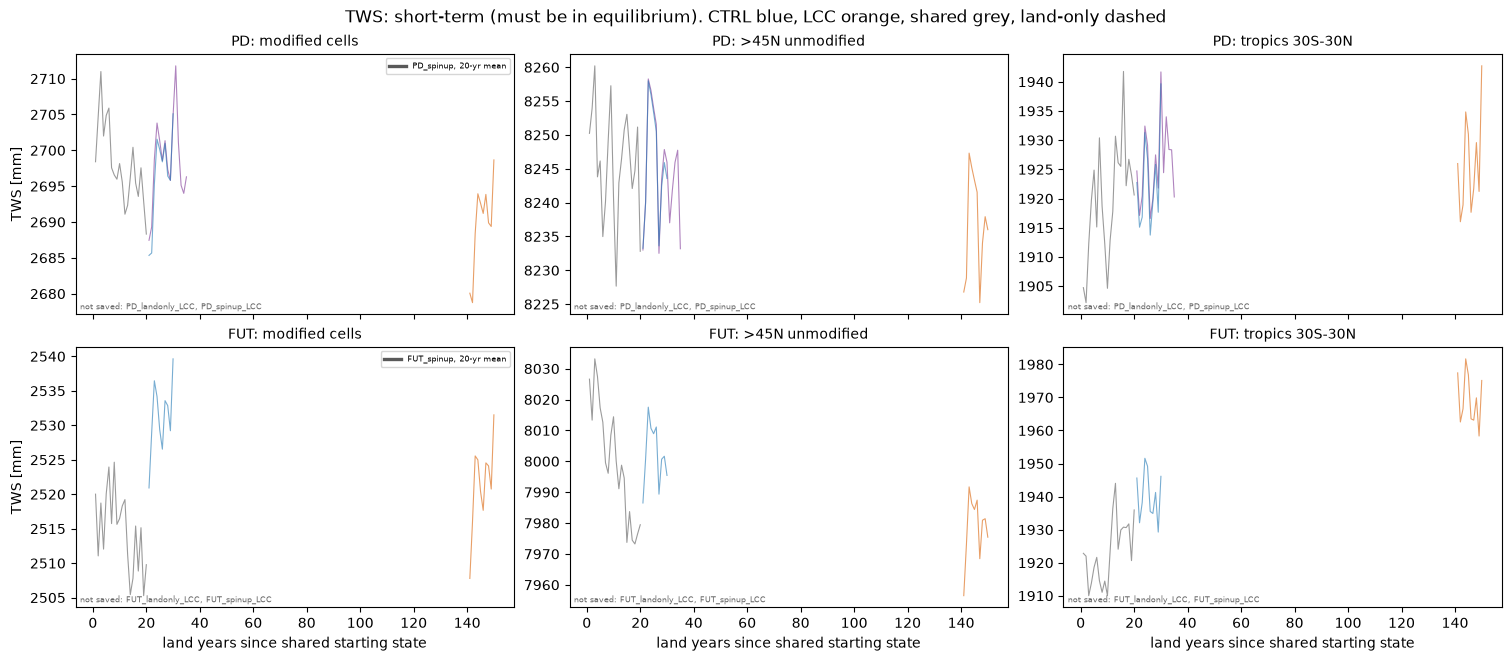

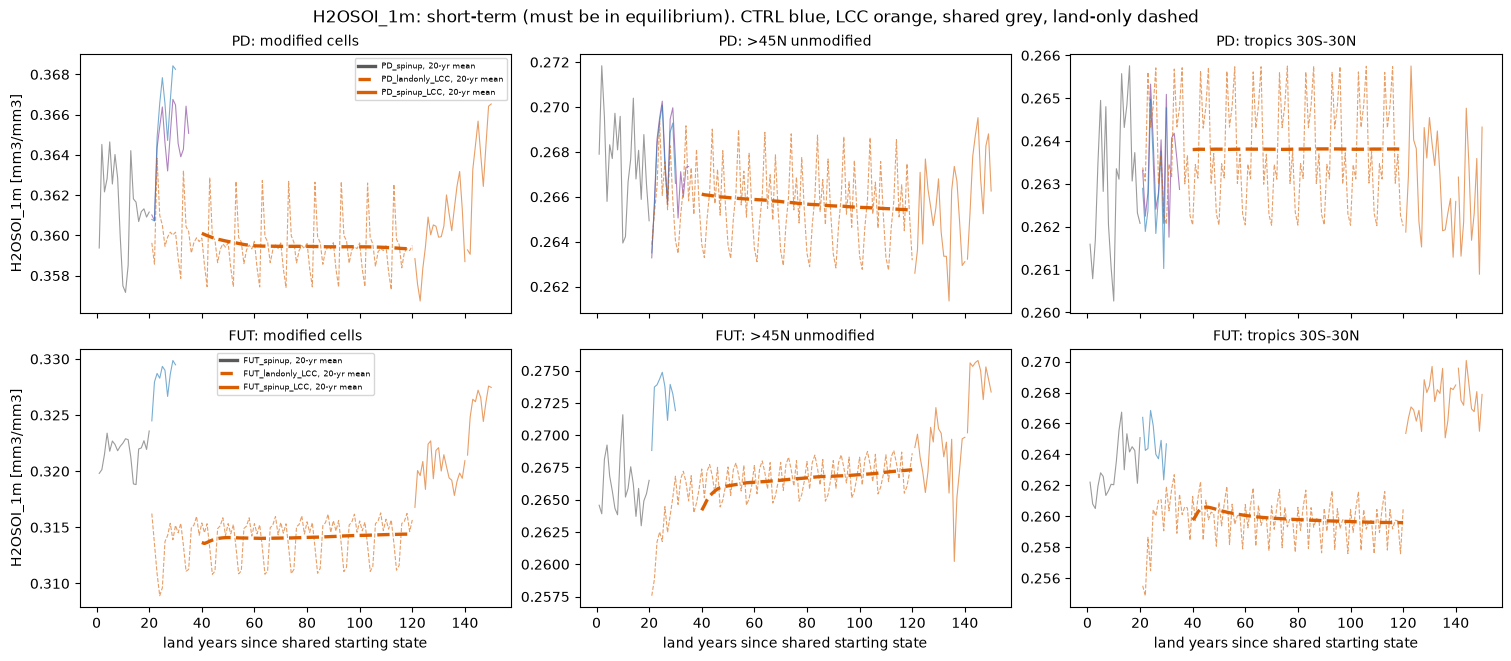

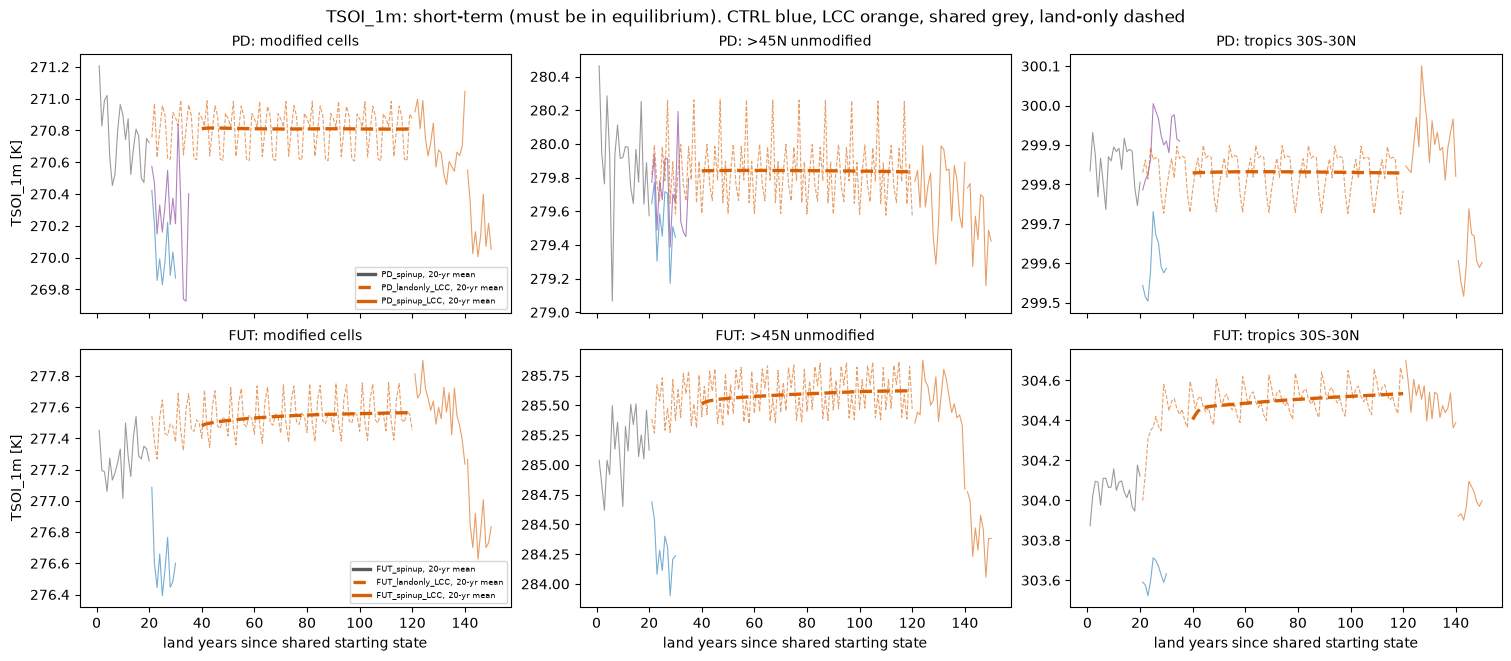

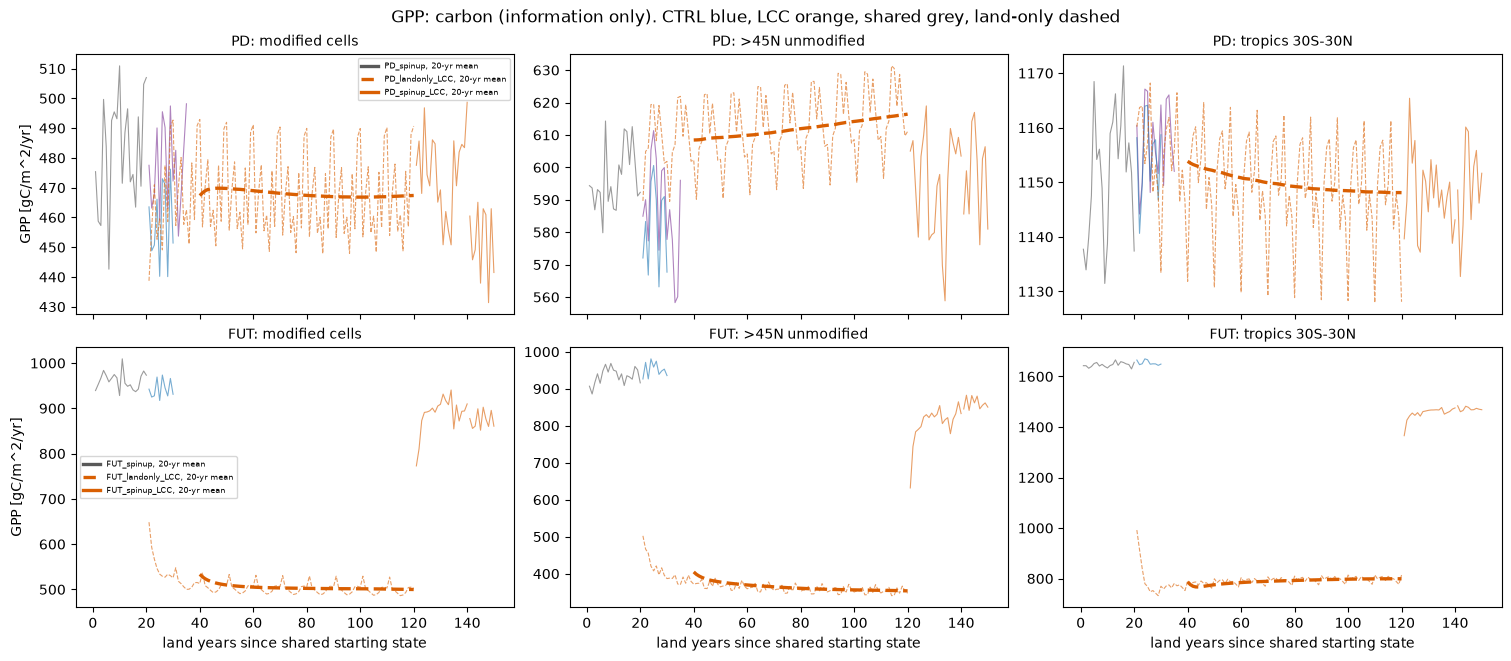

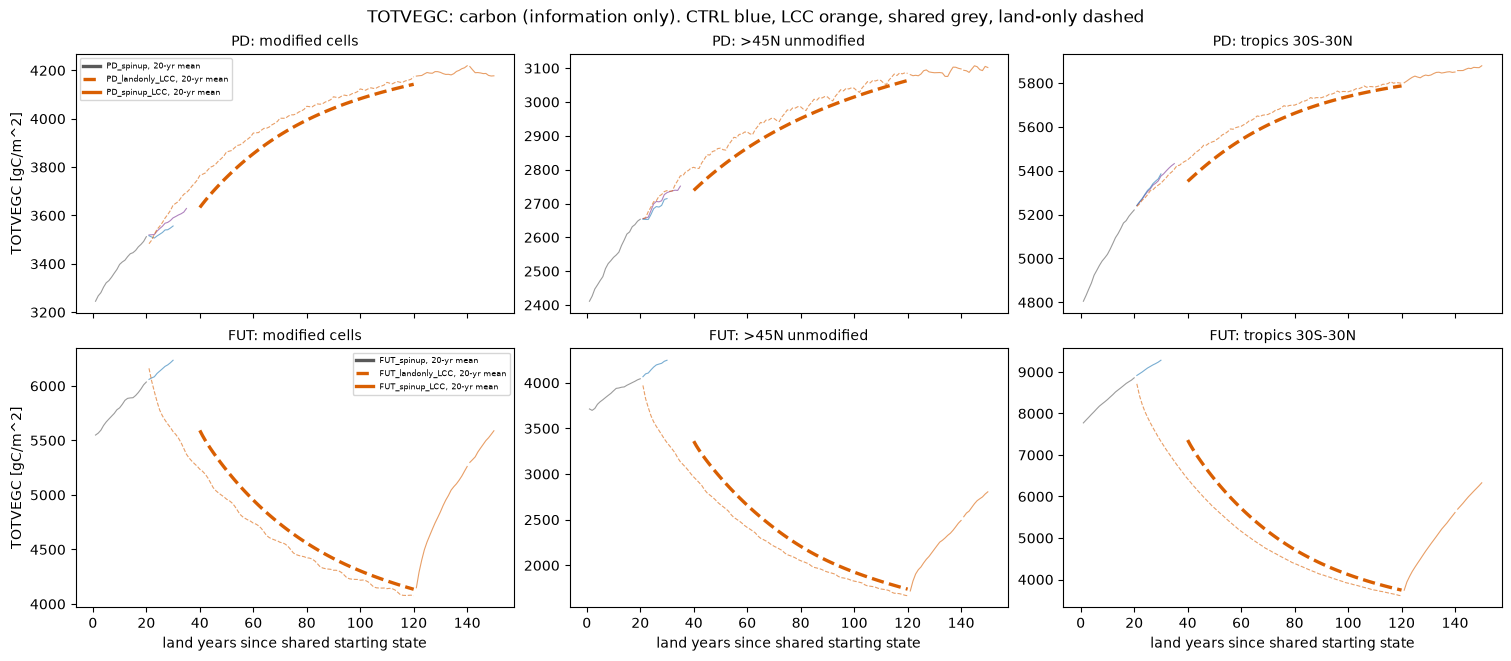

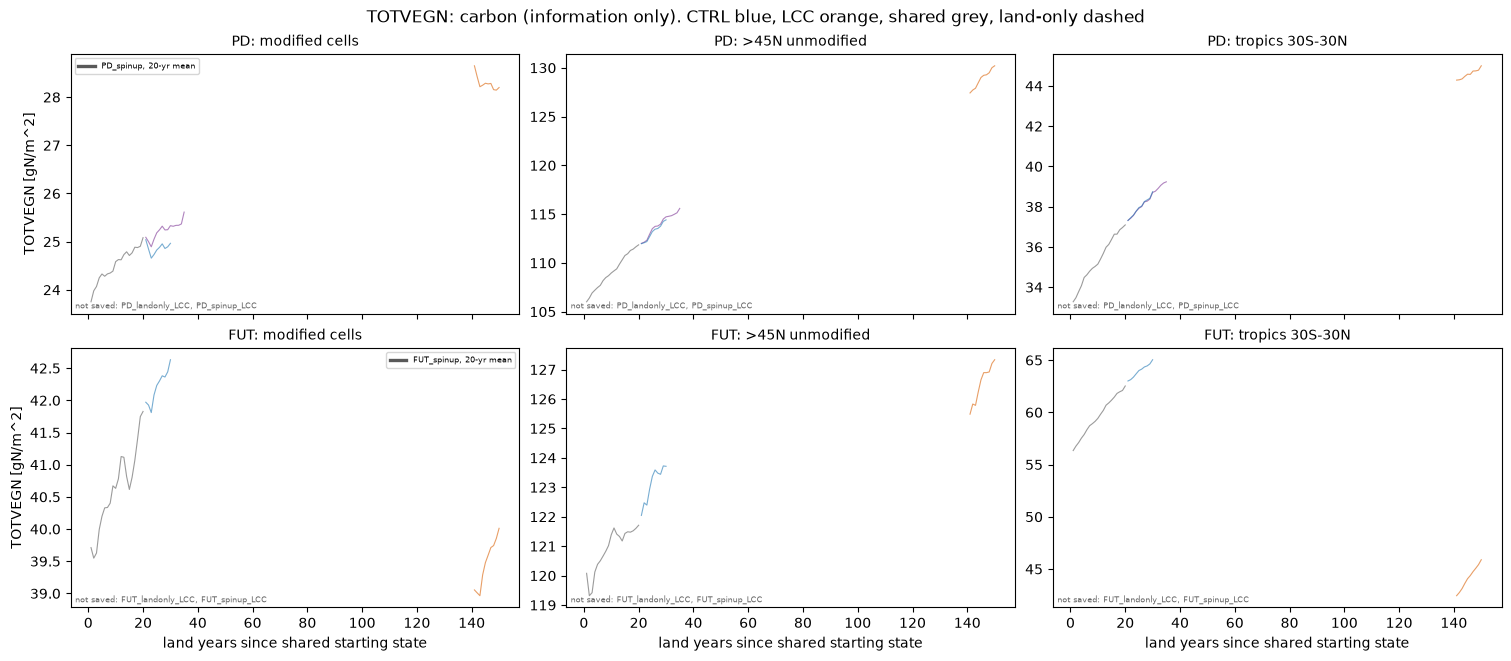

In [10]:
def units_of(v):
    stage = next(s for s in STAGES.index if v in ANN[s])
    return 'gC/m^2/yr' if v == 'GPP' else ANN[stage][v].attrs.get('units', '?')

def six_figure(v):
    fig, axes = plt.subplots(2, len(REGIONS), figsize=(5 * len(REGIONS), 6.5), sharex=True, layout='constrained')
    for i, period in enumerate(['PD', 'FUT']):
        group = STAGES[STAGES.period == period]
        for j, region in enumerate(REGIONS):
            ax = axes[i, j]
            for stage, s in group.iterrows():
                if (stage, region, v) not in SERIES:
                    continue
                y = SERIES[stage, region, v]
                ls = '--' if s.kind == 'land-only' else '-'
                ax.plot(AXIS[stage], y, color=COLOR[s.branch], lw=0.8, ls=ls, alpha=0.6)
                if y.sizes['year'] >= ROLL:
                    ax.plot(AXIS[stage], y.rolling(year=ROLL).mean(), color=COLOR[s.branch], lw=2.4, ls=ls,
                            label=f'{stage}, {ROLL}-yr mean')
            missing = [st for st in group.index if (st, region, v) not in SERIES]
            if missing:
                ax.text(0.01, 0.02, 'not saved: ' + ', '.join(missing), transform=ax.transAxes, fontsize=6, color='0.4')
            ax.set_title(f'{period}: {region}', fontsize=10)
            if j == 0:
                ax.set_ylabel(f'{v} [{units_of(v)}]')
            if i == 1:
                ax.set_xlabel('land years since shared starting state')
        axes[i, 0].legend(fontsize=6, loc='best')
    kind = 'short-term (must be in equilibrium)' if v in SHORT_TERM else 'carbon (information only)'
    fig.suptitle(f'{v}: {kind}. CTRL blue, LCC orange, shared grey, land-only dashed')
    fig.savefig(OUT / f'fig5_six_{v}.png', dpi=150)
    plt.show()

for v in SHORT_TERM + CARBON:
    six_figure(v)

## 9. Derivative of the 20-yr rolling mean (land-only stages)

`d(y) = (X[y] − X[y−20]) / 20`, in units per year. Only the 100-yr land-only stages are long enough (≥ 21 yr). For scale, the dotted lines show ± IAV / 20 yr. IAV is the SD of the detrended last 20 annual values: a drift inside the band changes the 20-yr mean by less than one year of noise per year.

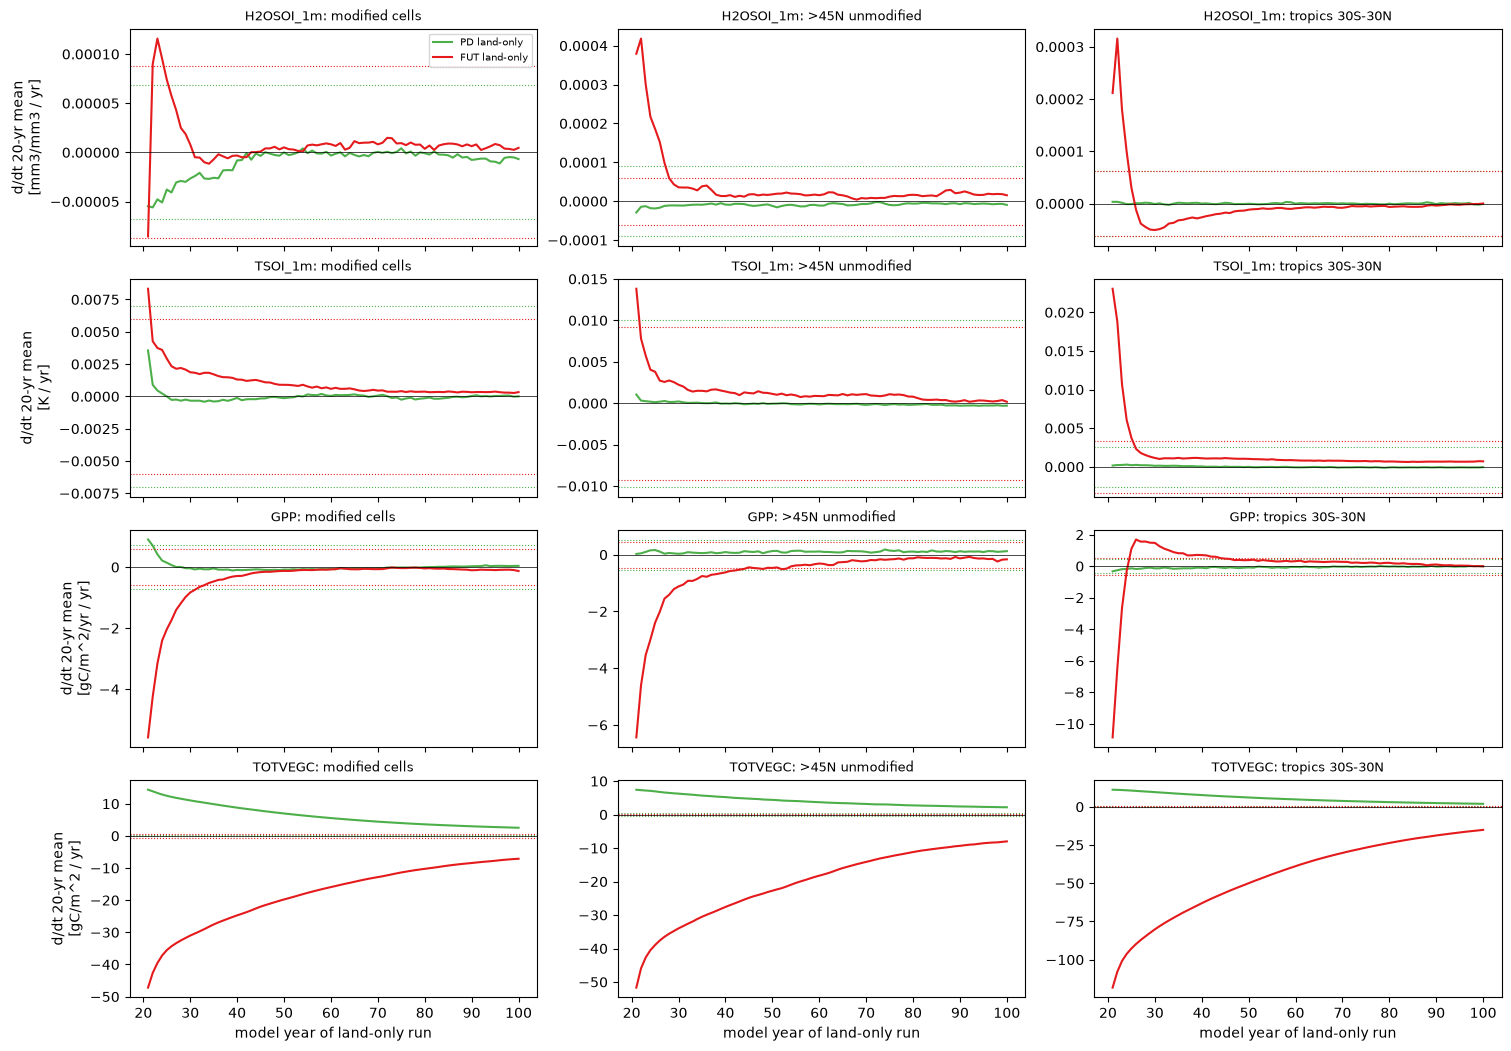

In [11]:
def detrended_sd(y):
    x = y.year.values.astype(float)
    return float(np.std(y.values - np.polyval(np.polyfit(x, y.values, 1), x), ddof=2))

landonly_vars = [v for v in SHORT_TERM + CARBON if all((f'{p}_landonly_LCC', r, v) in SERIES for p in ('PD', 'FUT') for r in REGIONS)]
fig, axes = plt.subplots(len(landonly_vars), len(REGIONS), figsize=(5 * len(REGIONS), 2.6 * len(landonly_vars)),
                         sharex=True, layout='constrained')
for i, v in enumerate(landonly_vars):
    for j, region in enumerate(REGIONS):
        ax = axes[i, j]
        for period, color in [('PD', '#4daf4a'), ('FUT', '#e41a1c')]:
            y = SERIES[f'{period}_landonly_LCC', region, v]
            d = y.rolling(year=ROLL).mean().diff('year')
            ax.plot(d.year, d, color=color, label=f'{period} land-only')
            band = detrended_sd(y.isel(year=slice(-ROLL, None))) / ROLL
            ax.axhline(band, color=color, ls=':', lw=0.8)
            ax.axhline(-band, color=color, ls=':', lw=0.8)
        ax.axhline(0, color='k', lw=0.5)
        ax.set_title(f'{v}: {region}', fontsize=9)
        if j == 0:
            ax.set_ylabel(f'd/dt {ROLL}-yr mean\n[{units_of(v)} / yr]')
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel('model year of land-only run')
fig.savefig(OUT / 'fig6_rolling_derivative_landonly.png', dpi=150)
plt.show()

## 10. Verdict tables: is the state drifting at the end of each stage?

For every stage: OLS trend over its last 10 years (per decade), and IAV = SD of the detrended last 10 annual values.
- `ratio = |trend per decade| / IAV`: below 1 means the drift over a decade is smaller than the year-to-year noise. This is descriptive, not a hard threshold.
- For the 100-yr land-only stages, the last value of the 20-yr rolling-mean derivative is shown too.
- Short-term variables get a flag; carbon variables are listed for information only, as % per decade.

In [12]:
rows = []
for (stage, region, v), y in SERIES.items():
    if v not in SHORT_TERM + CARBON:
        continue
    last = y.isel(year=slice(-10, None))
    trend = 10 * np.polyfit(last.year.values.astype(float), last.values, 1)[0]
    iav = detrended_sd(last)
    roll = y.rolling(year=ROLL).mean().diff('year')
    rows.append(dict(stage=stage, period=STAGES.loc[stage, 'period'], kind=STAGES.loc[stage, 'kind'], region=region,
                     variable=v, units=units_of(v), mean=float(last.mean()), trend_per_decade=trend, iav_sd=iav,
                     ratio=abs(trend) / iav if iav > 0 else np.nan,
                     trend_pct_per_decade=100 * trend / float(last.mean()),
                     roll20_deriv_last=float(roll[-1]) if y.sizes['year'] > ROLL else np.nan))
verdict = pd.DataFrame(rows)
verdict['drift_below_noise'] = verdict.ratio < 1
verdict.to_csv(OUT / 'verdict_six_variables.csv', index=False)

order = list(STAGES.index)
short = verdict[verdict.variable.isin(SHORT_TERM)]
print('SHORT-TERM: ratio |trend/decade| / IAV  (< 1 = drift below noise)')
display(short.pivot_table(index=['variable', 'region'], columns='stage', values='ratio')
        .reindex(columns=[s for s in order if s in short.stage.values]).round(2))
print('SHORT-TERM: trend per decade (native units)')
display(short.pivot_table(index=['variable', 'region', 'units'], columns='stage', values='trend_per_decade')
        .reindex(columns=[s for s in order if s in short.stage.values]).round(4))
print('CARBON (information only): trend, % per decade')
carbon = verdict[verdict.variable.isin(CARBON)]
display(carbon.pivot_table(index=['variable', 'region'], columns='stage', values='trend_pct_per_decade')
        .reindex(columns=[s for s in order if s in carbon.stage.values]).round(1))

SHORT-TERM: ratio |trend/decade| / IAV  (< 1 = drift below noise)


stage                      PD_spinup  PD_met  CTRL_PD  PD_landonly_LCC  \
variable  region                                                         
H2OSOI_1m >45N unmodified       0.04    0.75     1.29             0.17   
          modified cells        1.14    0.63     4.22             0.26   
          tropics 30S-30N       1.43    0.72     0.41             1.56   
TSOI_1m   >45N unmodified       0.92    0.88     1.17             0.56   
          modified cells        0.81    1.26     1.73             0.36   
          tropics 30S-30N       2.88    0.95     1.21             2.16   
TWS       >45N unmodified       0.45    0.66     0.09              NaN   
          modified cells        0.67    0.65     3.14              NaN   
          tropics 30S-30N       0.74    0.93     1.26              NaN   

stage                      PD_spinup_LCC  LCC_PD  FUT_spinup  CTRL_FUT  \
variable  region                                                         
H2OSOI_1m >45N unmodified           0.30    1.26        0.52      0.43   
          modified cells            0.26    4.10        0.72      2.37   
          tropics 30S-30N           3.34    0.26        0.87      1.86   
TSOI_1m   >45N unmodified           2.06    1.46        0.77      2.09   
          modified cells            2.76    1.53        0.79      1.44   
          tropics 30S-30N           1.02    0.76        0.24      1.25   
TWS       >45N unmodified            NaN    0.13        4.17      0.34   
          modified cells             NaN    3.40        1.77      1.84   
          tropics 30S-30N            NaN    1.37        0.31      0.49   

stage                      FUT_landonly_LCC  FUT_spinup_LCC  LCC_FUT  
variable  region                                                      
H2OSOI_1m >45N unmodified              0.34            0.26     0.33  
          modified cells               1.03            0.66     2.70  
          tropics 30S-30N              0.56            0.60     1.76  
TSOI_1m   >45N unmodified              0.88            4.49     2.00  
          modified cells               1.09            2.63     1.43  
          tropics 30S-30N              0.49            1.23     1.61  
TWS       >45N unmodified               NaN             NaN     0.69  
          modified cells                NaN             NaN     2.78  
          tropics 30S-30N               NaN             NaN     0.77

SHORT-TERM: trend per decade (native units)


stage                              PD_spinup  PD_met  CTRL_PD  \
variable  region          units                                 
H2OSOI_1m >45N unmodified mm3/mm3    -0.0001 -0.0012   0.0026   
          modified cells  mm3/mm3     0.0021  0.0008   0.0075   
          tropics 30S-30N mm3/mm3    -0.0018  0.0008   0.0006   
TSOI_1m   >45N unmodified K          -0.1949 -0.2284  -0.2233   
          modified cells  K          -0.1150 -0.4168  -0.3140   
          tropics 30S-30N K          -0.1237 -0.0361   0.0849   
TWS       >45N unmodified mm          3.8697 -4.4535  -0.7909   
          modified cells  mm         -2.4067 -3.6458  15.2187   
          tropics 30S-30N mm          5.9435  7.0194  10.0759   

stage                              PD_landonly_LCC  PD_spinup_LCC   LCC_PD  \
variable  region          units                                              
H2OSOI_1m >45N unmodified mm3/mm3           0.0003         0.0006   0.0025   
          modified cells  mm3/mm3           0.0004         0.0004   0.0070   
          tropics 30S-30N mm3/mm3          -0.0019        -0.0023   0.0004   
TSOI_1m   >45N unmodified K                -0.1190        -0.3238  -0.2872   
          modified cells  K                -0.0526         0.3506  -0.2660   
          tropics 30S-30N K                -0.1012        -0.0537   0.0501   
TWS       >45N unmodified mm                   NaN            NaN   1.1146   
          modified cells  mm                   NaN            NaN  14.9954   
          tropics 30S-30N mm                   NaN            NaN  11.3624   

stage                              FUT_spinup  CTRL_FUT  FUT_landonly_LCC  \
variable  region          units                                             
H2OSOI_1m >45N unmodified mm3/mm3     -0.0007    0.0008           -0.0004   
          modified cells  mm3/mm3      0.0012    0.0032            0.0018   
          tropics 30S-30N mm3/mm3     -0.0012   -0.0023           -0.0007   
TSOI_1m   >45N unmodified K           -0.1438   -0.4213           -0.1675   
          modified cells  K           -0.0944   -0.2829           -0.1335   
          tropics 30S-30N K            0.0179    0.0723            0.0345   
TWS       >45N unmodified mm         -28.2375   -3.6155               NaN   
          modified cells  mm          -8.3057    8.9610               NaN   
          tropics 30S-30N mm          -2.3134   -3.8520               NaN   

stage                              FUT_spinup_LCC  LCC_FUT  
variable  region          units                             
H2OSOI_1m >45N unmodified mm3/mm3         -0.0009   0.0006  
          modified cells  mm3/mm3         -0.0007   0.0040  
          tropics 30S-30N mm3/mm3         -0.0009  -0.0022  
TSOI_1m   >45N unmodified K               -0.7446  -0.3848  
          modified cells  K               -0.3367  -0.2569  
          tropics 30S-30N K               -0.0784   0.0969  
TWS       >45N unmodified mm                  NaN   7.5172  
          modified cells  mm                  NaN  14.2647  
          tropics 30S-30N mm                  NaN  -6.2271

CARBON (information only): trend, % per decade


stage                     PD_spinup  PD_met  CTRL_PD  PD_landonly_LCC  \
variable region                                                         
GPP      >45N unmodified       -0.0    -4.4      0.2              1.1   
         modified cells         4.5    -1.6      1.0              5.3   
         tropics 30S-30N       -1.6     0.5      0.3             -1.8   
TOTVEGC  >45N unmodified        4.7     1.9      2.8              1.2   
         modified cells         3.2     2.1      1.5              0.6   
         tropics 30S-30N        3.9     2.4      2.9              0.3   
TOTVEGN  >45N unmodified        2.8     1.7      2.6              NaN   
         modified cells         1.7     1.0      0.3              NaN   
         tropics 30S-30N        5.1     3.6      4.0              NaN   

stage                     PD_spinup_LCC  LCC_PD  FUT_spinup  CTRL_FUT  \
variable region                                                         
GPP      >45N unmodified            5.1    -0.3         0.4      -0.3   
         modified cells            10.3    -1.7        -0.4       1.1   
         tropics 30S-30N           -0.9     0.8        -0.3      -0.9   
TOTVEGC  >45N unmodified            0.7     0.4         3.1       4.9   
         modified cells             1.0    -0.9         3.5       3.3   
         tropics 30S-30N            0.2     0.4         5.9       4.4   
TOTVEGN  >45N unmodified            NaN     2.4         0.2       1.5   
         modified cells             NaN    -1.3         2.4       1.9   
         tropics 30S-30N            NaN     1.7         4.7       3.4   

stage                     FUT_landonly_LCC  FUT_spinup_LCC  LCC_FUT  
variable region                                                      
GPP      >45N unmodified               0.3             1.3     -0.9  
         modified cells               -1.8            -3.9      0.7  
         tropics 30S-30N              -1.2             0.0     -0.3  
TOTVEGC  >45N unmodified              -4.7            12.8     11.3  
         modified cells               -2.0             7.5      6.1  
         tropics 30S-30N              -3.8            15.9     11.7  
TOTVEGN  >45N unmodified               NaN             NaN      1.6  
         modified cells                NaN             NaN      3.0  
         tropics 30S-30N               NaN             NaN      8.7

## 11. Do the members share the same short-term state? LCC − CTRL, 2001–2009

This is the short-term counterpart of section 5. Δ is shown in units of CTRL's interannual SD, with Welch p on the 9 annual values. Outside the modified cells Δ should be ≈ 0.
CO₂ acts on stomata and therefore on transpiration, so a CO₂-damaged vegetation could also shift soil water (b).

,period,region,variable,units,CTRL,LCC,delta,delta_in_iav,p_welch
0,PD,modified cells,TWS,mm,2697.6976,2690.7444,-6.9532,-1.2636,0.0160
1,PD,modified cells,H2OSOI_1m,mm3/mm3,0.3661,0.3640,-0.0020,-0.8395,0.0885
2,PD,modified cells,TSOI_1m,K,269.9867,270.1585,0.1718,1.1690,0.0224
3,PD,>45N unmodified,TWS,mm,8247.0265,8237.7076,-9.3189,-1.1594,0.0215
4,PD,>45N unmodified,H2OSOI_1m,mm3/mm3,0.2679,0.2674,-0.0005,-0.2939,0.5313
5,PD,>45N unmodified,TSOI_1m,K,279.5173,279.4986,-0.0187,-0.0936,0.8461
6,PD,tropics 30S-30N,TWS,mm,1922.9223,1925.9577,3.0354,0.3516,0.4774
7,PD,tropics 30S-30N,H2OSOI_1m,mm3/mm3,0.2630,0.2627,-0.0003,-0.1993,0.6788
8,PD,tropics 30S-30N,TSOI_1m,K,299.6012,299.6154,0.0143,0.1954,0.6735
9,FUT,modified cells,TWS,mm,2532.3046,2522.8411,-9.4635,-2.2684,0.0004


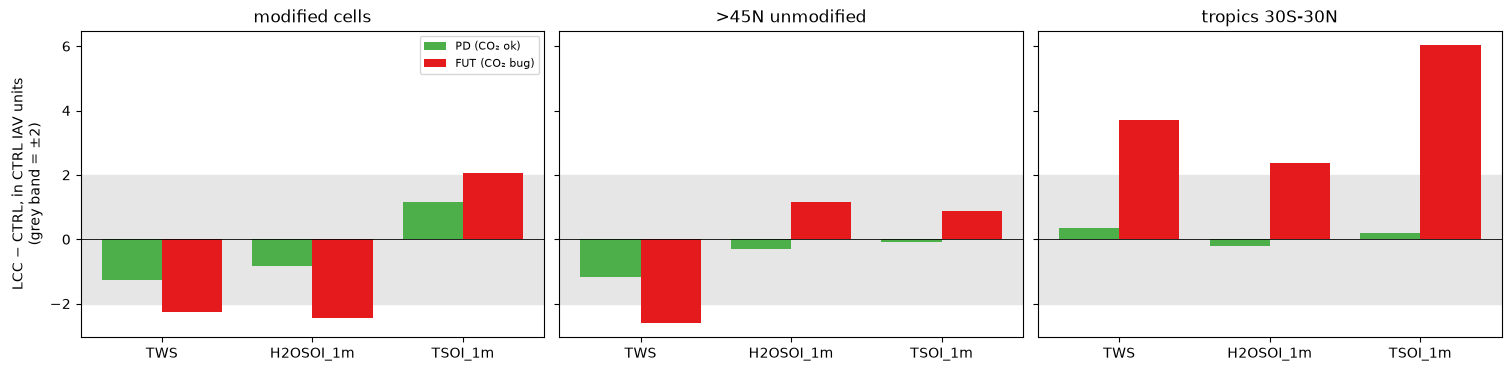

In [13]:
rows = []
for period in ('PD', 'FUT'):
    for region in REGIONS:
        for v in SHORT_TERM:
            c = SERIES[f'CTRL_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            l = SERIES[f'LCC_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            sd = float(c.std(ddof=1))
            rows.append(dict(period=period, region=region, variable=v, units=units_of(v),
                             CTRL=float(c.mean()), LCC=float(l.mean()), delta=float(l.mean() - c.mean()),
                             delta_in_iav=float(l.mean() - c.mean()) / sd,
                             p_welch=stats.ttest_ind(l.values, c.values, equal_var=False).pvalue))
short_end = pd.DataFrame(rows)
short_end.to_csv(OUT / 'endstate_short_term.csv', index=False)
display(short_end.round(4))

fig, axes = plt.subplots(1, len(REGIONS), figsize=(5 * len(REGIONS), 3.6), sharey=True, layout='constrained')
x = np.arange(len(SHORT_TERM))
for ax, region in zip(axes, REGIONS):
    sub = short_end[short_end.region == region].set_index(['period', 'variable']).delta_in_iav
    ax.bar(x - 0.2, [sub['PD', v] for v in SHORT_TERM], 0.4, color='#4daf4a', label='PD (CO₂ ok)')
    ax.bar(x + 0.2, [sub['FUT', v] for v in SHORT_TERM], 0.4, color='#e41a1c', label='FUT (CO₂ bug)')
    ax.axhline(0, color='k', lw=0.6)
    ax.axhspan(-2, 2, color='0.9', zorder=0)
    ax.set(xticks=x, xticklabels=SHORT_TERM, title=region)
axes[0].set_ylabel('LCC − CTRL, in CTRL IAV units\n(grey band = ±2)')
axes[0].legend(fontsize=8)
fig.savefig(OUT / 'fig7_short_term_endstate.png', dpi=150)
plt.show()

## Summary (run 2026-10-22, outputs saved in this notebook and in `check_CO2_bug_in_land_only_six_variables_outputs/`)

Sections 1–7 are the same as in `check_CO2_bug_in_land_only.ipynb`; see its summary. This summary covers sections 8–11.

👉 **Short-term variables (the requirement).** Within each stage, TWS, H2OSOI and TSOI at 1.06 m settle within ~10–30 years. Their drift at hand-over is mostly comparable to the interannual noise (a, fig. 6, `verdict_six_variables.csv`).
**But in FUT the two members do not share the same short-term state**: the CO₂-damaged LCC vegetation leaves the soil wetter and warmer, especially in the tropics (a, fig. 7). **In PD, the short-term state matches between members** (all |Δ| ≤ 1.3 IAV).

**1. Rolling-mean derivative, land-only stages (fig. 6, (a)).**
- **PD:** H2OSOI and TSOI derivatives are ≈ 0 and inside the noise band from ~year 30 on, so the short-term state is in equilibrium.
- **FUT:** H2OSOI settles by ~year 30–40. TSOI keeps a small positive derivative (warming 0.0003–0.001 K/yr at year 100), inside the noise band after ~year 25–30. This is the soil adjusting to the collapsed vegetation (b).
- **Carbon:** PD TOTVEGC still rises (+2–3 gC m⁻² yr⁻¹ at year 100); FUT TOTVEGC is still falling (−7 to −15). GPP ≈ 0 in both after ~year 50.

**2. Stage boundaries (fig. 5, (a); interpretation (b)).**
- TSOI jumps by ~0.5–1 K between stages: land-only (datm cplhist) is warmer than coupled, and nudged runs are colder than free spin-ups. These are forcing offsets, not drift.
- After the land-only stage, the coupled LCC spin-ups take most of their 20 years to shed that offset. TSOI trend at the end of `FUT_spinup_LCC`: −0.74 K/decade at >45°N unmodified (ratio 4.5 to IAV) and −0.34 K/decade in the modified cells. At the end of `PD_spinup_LCC`: +0.35 K/decade in the modified cells (ratio 2.8).
- So the short-term state handed to LCC_FUT and LCC_PD is **not fully settled in soil temperature** (b).

**3. Nudged runs (table, (a)).** 9-year trends are larger than IAV in some cells (e.g. H2OSOI in the modified cells, ratio 2–4), but **CTRL and LCC trend alike**:

| Period | Variable (modified cells) | CTRL | LCC |
|---|---|---|---|
| PD | H2OSOI, per decade | +0.0075 | +0.0070 |
| PD | TSOI, K per decade | −0.31 | −0.27 |
| FUT | H2OSOI, per decade | +0.0032 | +0.0040 |
| FUT | TSOI, K per decade | −0.28 | −0.26 |

These trends come from the nudged 2001–2009 meteorology, not from spin-up drift, and cancel in LCC − CTRL (b).

**4. LCC − CTRL short-term state, 2001–2009 (fig. 7, `endstate_short_term.csv`, (a)):**

| Region | PD | FUT |
|---|---|---|
| modified cells | TWS −7 mm (−1.3 IAV), TSOI +0.17 K (+1.2) | TWS −9 mm (−2.3), H2OSOI −0.002 (−2.4), TSOI +0.25 K (+2.1) |
| >45°N unmodified | TWS −9 mm (−1.2), others ≈ 0 | TWS −23 mm (−2.6), H2OSOI +1.2, TSOI +0.16 K (+0.9) |
| tropics | all within ±0.4 IAV | **TWS +29 mm (+3.7), H2OSOI +0.003 (+2.4), TSOI +0.37 K (+6.0)** |

- In FUT the far-field soil is wetter and warmer in LCC. This fits less leaf area → less transpiration and less shading (b).
- In the modified cells, part of Δ is the real land-cover signal. PD shows its size (≈ 1 IAV).

**Bottom line for the experiment (b).**
- **PD:** short-term variables are in equilibrium and consistent between members, so the requirement is met. Carbon is still drifting, which the user accepts.
- **FUT:** the short-term state is stable but different between members, through the CO₂-damaged vegetation. The far-field TSOI/TWS offset is what Total_FUT would see as a "land-cover effect". The bug therefore matters for the short-term variables too, not only for carbon.

**Gaps:** TWS and TOTVEGN were not saved in the land-only runs and LCC coupled spin-ups (c for those stages). The trend-vs-IAV ratio over 10 years is descriptive, not a test.

**Met run (purple, added 2026-10-22).** The free PD met run continues the spin-up level. The nudged CTRL_PD over the same years is cooler: TSOI@1 m −0.28 K on global land, −0.32 K in the modified cells. The free → nudged step is therefore mostly the nudging effect, not spin-up drift; see `../impact-of-nudging-on-land/`.